FIGURE S3

Shahlo Solieva 

Created 08032026

RMSD to starting structure. Align by framework then calculate CA RMSD.

In [1]:
import numpy as np
import mdtraj as md
import pickle
import matplotlib.pyplot as plt

# RMSD

In [11]:
def get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1]):
    # Import atom indices for FR:
    fr_indices_data_path = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/'
    fr_indices = np.load(f'{fr_indices_data_path}{sys_name}-FR-indices-FAH.npy')
    
    # Import starting pdb structure
    #cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50/data/apo/{sys_name}/"
    cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50/data/apo/{sys_name}/cluster-r215-to-reduce-nclusters/"
    
    pdb = md.load(f'{cluster_dir_path}prot_masses_uniform.pdb')

    # Select variable region atom indices (heavy + light chains)
    start_of_VH = VH_resis[0]
    end_of_VH   = VH_resis[1]
    start_of_VL = VL_resis[0]
    end_of_VL   = VL_resis[1]
    variable_indices = np.concatenate([pdb.topology.select(f'chainid {target_chains[0]} and residue {start_of_VH} to {end_of_VH} and name CA'),
                                       pdb.topology.select(f'chainid {target_chains[1]} and residue {start_of_VL} to {end_of_VL} and name CA')])
    print(len(variable_indices), variable_indices[0:3], variable_indices[-3:])

    # Import cluster centers:
    
    #file=f"{cluster_dir_path}cluster-centers.pickle"
    file=f"{cluster_dir_path}cluster-centers-r215.pickle"
    with open(file, 'rb') as file:
        centers=pickle.load(file) # load in cluster centers.

    # Import eq probabilities:
    eq_probs = np.load(f'{cluster_dir_path}eq_probs_msm_100.npy')

    # RMSD, align by FR
    rmsd_values = []
    for center_ind in range(len(centers)):
        centers[center_ind].superpose(pdb, atom_indices=variable_indices)
        starting_xyz = pdb.xyz[:, variable_indices, :]
        center_xyz = centers[center_ind].xyz[0, variable_indices, :]
        rmsd = np.sqrt(np.mean(np.sum((starting_xyz - center_xyz)**2, axis=2), axis=1))
        rmsd_values.append(rmsd[0]*10) # convert nm to Angstroms
    return rmsd_values, eq_probs

In [5]:
# colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']

# PGT121

In [7]:
lineage = 'PGT121' 

sys_name = 'PGT121_naive_VC'
VH_resis = ["1","132"]
VL_resis = ["1","109"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'PGT121_mature_VC'
VH_resis = ["1","132"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

241 [ 4 21 37] [5064 5078 5094]
237 [ 4 21 38] [5006 5020 5036]


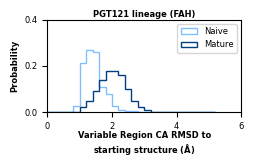

In [8]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,5.4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('PGT121 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.ylim(0,0.4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# 1-18

In [5]:
lineage = '1-18' 

sys_name = 'Ab118_naive_VC'
VH_resis = ["1","125"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'Ab118_mature_VC'
VH_resis = ["1","131"]
VL_resis = ["1","108"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

233 [ 4 21 37] [4930 4945 4964]
239 [ 4 21 28] [5116 5128 5150]


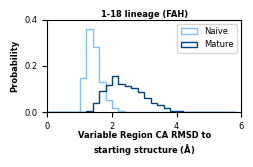

In [6]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,6,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('1-18 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.ylim(0,0.4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# CAP256

In [12]:
lineage='CAP256'

sys_name = 'CAP256_naive_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_mature_VC'
VH_resis = ["1","145"]
VL_resis = ["1","111"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

255 [ 4 21 37] [5176 5190 5206]
256 [ 4 21 37] [5289 5308 5324]


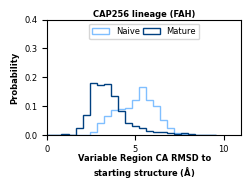

In [13]:
plt.figure(figsize=[2.5,1.5])
bins=np.arange(0,10,0.4)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CAP256 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
#plt.legend(fontsize=6, loc='center left', bbox_to_anchor=(1, 0.5))
plt.legend(fontsize=6, loc='upper center', ncols=4, columnspacing=0.4) 
plt.xlim(0,11)
plt.ylim(0,0.4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}-FAH-styleB.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH103

In [46]:
lineage='CH103'

sys_name = 'CH103_naive_VC'
VH_resis = ["1","121"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_mature_VC'
VH_resis = ["1","121"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

229 [ 4 21 37] [4859 4875 4894]
226 [ 4 21 37] [4801 4817 4836]


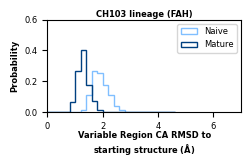

In [48]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4.8,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH103 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,7)
plt.ylim(0,0.6)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH65

In [50]:
lineage = 'CH65'

sys_name = 'CH65_naive_VC'
VH_resis = ["1","126"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH65_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])



234 [ 4 21 37] [4907 4921 4937]
234 [ 4 19 35] [4896 4910 4926]


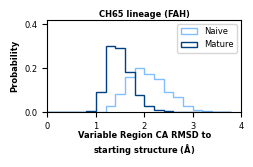

In [51]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH65 lineage (FAH)', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,4)
plt.ylim(0,0.42)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}-FAH.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()